In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
import os

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
dataset_path = r"C:\Users\SURAJ CHOUGULE\Downloads\brain tumour"

train_path = dataset_path + r"\Training"
test_path = dataset_path + r"\Testing"

In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    train_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    train_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="categorical",
    subset="validation"
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(150, 150),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

class_names = list(train_data.class_indices.keys())

print("Classes:", class_names)

Found 2297 images belonging to 4 classes.
Found 573 images belonging to 4 classes.
Found 394 images belonging to 4 classes.
Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


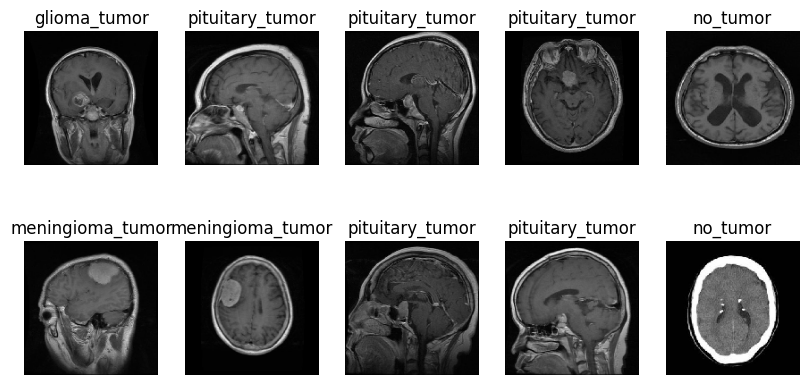

In [ ]:
images, labels = next(train_data)

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis("off")

plt.show()

Text(0.5, 1.0, 'pituitary_tumor')

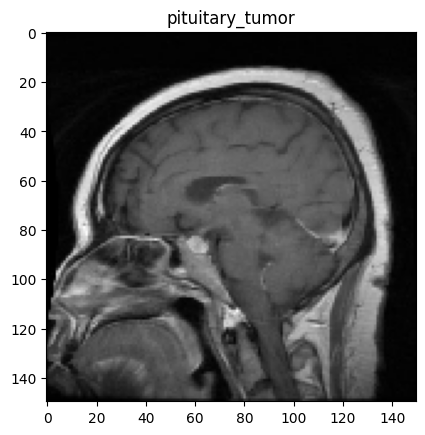

In [ ]:
plt.imshow(images[1])
plt.title(class_names[np.argmax(labels[1])])

In [ ]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(4, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,868 (40.58 MB)

 Trainable params: 10,636,868 (40.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_data,
    epochs=20,
    validation_data=val_data
)

Epoch 1/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 33s 436ms/step - accuracy: 0.4942 - loss: 1.3771 - val_accuracy: 0.3857 - val_loss: 1.1511
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 38s 530ms/step - accuracy: 0.8061 - loss: 0.5178 - val_accuracy: 0.5881 - val_loss: 0.9696
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 32s 448ms/step - accuracy: 0.8793 - loss: 0.3025 - val_accuracy: 0.6178 - val_loss: 1.0613
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 31s 423ms/step - accuracy: 0.9372 - loss: 0.1757 - val_accuracy: 0.5742 - val_loss: 1.1777
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 34s 465ms/step - accuracy: 0.9651 - loss: 0.1005 - val_accuracy: 0.6702 - val_loss: 1.1348
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 31s 432ms/step - accuracy: 0.9799 - loss: 0.0774 - val_accuracy: 0.6789 - val_loss: 1.2938
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 30s 419ms/step - accuracy: 0.9657 - loss: 0.0936 - val_accuracy: 0.6056 - val_loss: 1.5835
Epoch 8/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 31s 426ms/step - accuracy: 0.9899 - loss: 0.0433 - val_accu

In [ ]:
loss, acc = model.evaluate(test_data)

print("Test Accuracy:", acc)
print("Test Loss:", loss)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 147ms/step - accuracy: 0.5019 - loss: 15.2170
Test Accuracy: 0.6522842645645142
Test Loss: 8.171687126159668


In [ ]:
test_data.reset()

pred = model.predict(test_data)
pred_classes = np.argmax(pred, axis=1)

print("Actual:", test_data.classes[:10])
print("Predicted:", pred_classes[:10])

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step
Actual: [0 0 0 0 0 0 0 0 0 0]
Predicted: [2 2 1 2 2 1 1 2 1 3]


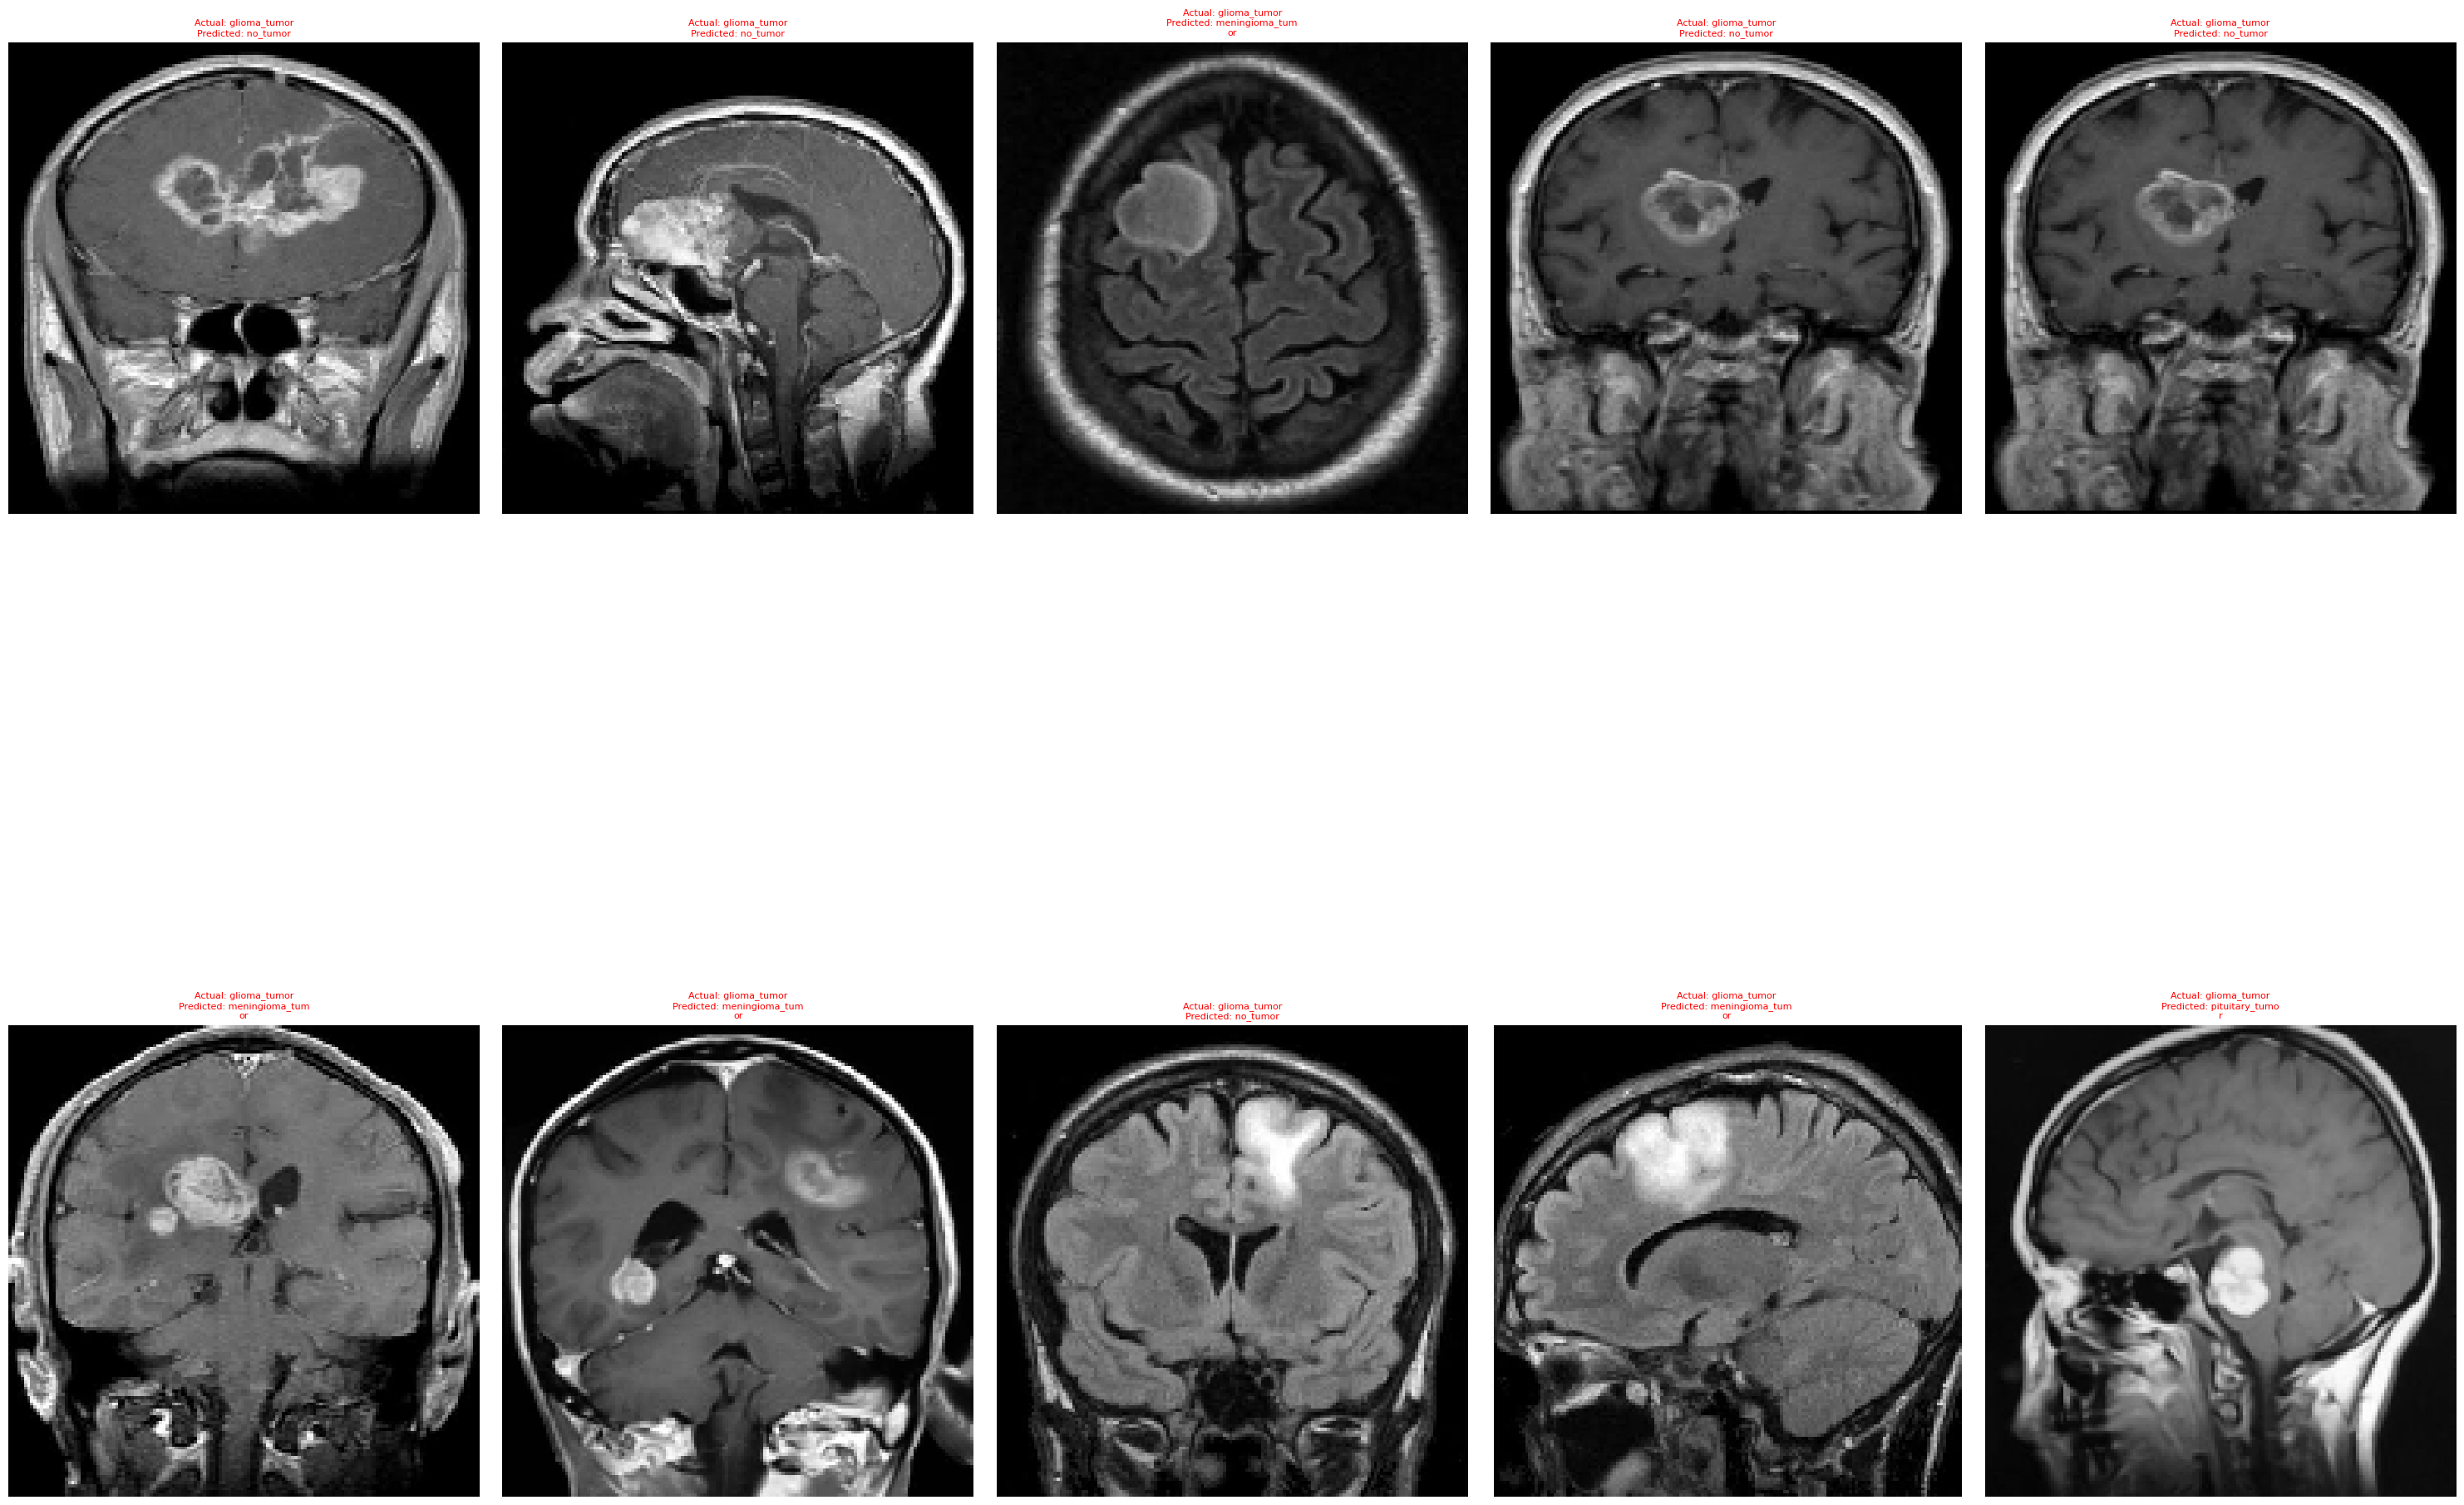

In [ ]:
import textwrap

test_data.reset()
images, labels = next(test_data)

plt.figure(figsize=(30, 30))

for i in range(10):
    actual = np.argmax(labels[i])
    pred = pred_classes[i]

    plt.subplot(2, 5, i+1)
    plt.imshow(images[i])

    actual_name = textwrap.fill(class_names[actual], width=14)
    pred_name = textwrap.fill(class_names[pred], width=14)

    plt.title(f"Actual: {actual_name}\nPredicted: {pred_name}",
              color='green' if actual == pred else 'red',
              fontsize=8)

    plt.axis('off')

plt.tight_layout(pad=2)
plt.show()

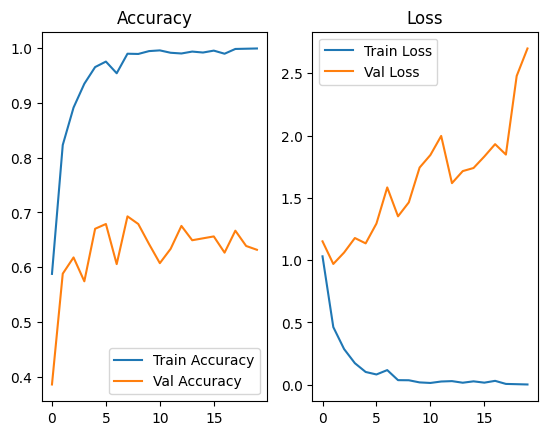

In [ ]:
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

plt.show()

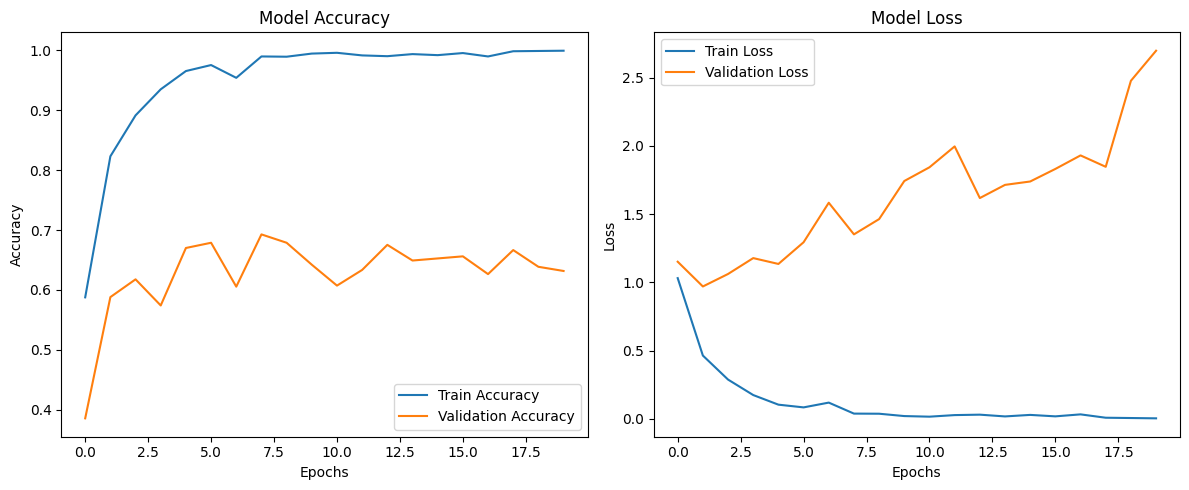

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

                  precision    recall  f1-score   support

    glioma_tumor       0.94      0.17      0.29       100
meningioma_tumor       0.59      0.99      0.74       115
        no_tumor       0.66      0.96      0.78       105
 pituitary_tumor       0.83      0.34      0.48        74

        accuracy                           0.65       394
       macro avg       0.76      0.62      0.57       394
    weighted avg       0.74      0.65      0.59       394



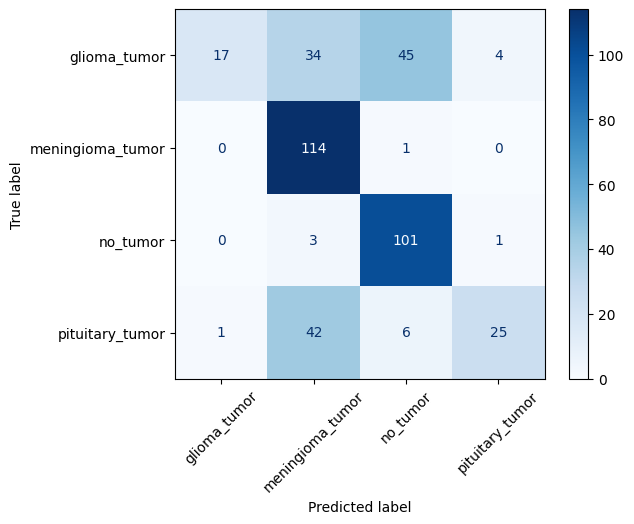

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_data.reset()
y_pred = np.argmax(model.predict(test_data, verbose=0), axis=1)
y_true = test_data.classes

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    cmap='Blues', xticks_rotation=45
)
plt.show()